# Assignment 2: Machine Learning Exploration Project
## Predicting hourly bike-share demand in Washington, D.C.

**Name:** Felex Hill
**Student ID:** 221324454

This notebook follows the eight parts of the assignment:

1. Dataset and problem definition
2. Data exploration
3. Data preparation
4. Initial machine learning model
5. Model complexity and generalization
6. Improving the model
7. Experimental analysis
8. Conclusions

## Part 1: Dataset and problem definition

### Dataset

- **Name:** Bike Sharing Dataset (hourly data)
- **Source:** UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset
- **Creator:** Hadi Fanaee-T, donated to UCI on 19 December 2013
- **Licence:** Creative Commons Attribution 4.0 International (CC BY 4.0), which allows use for any purpose with attribution
- **Citation:** Fanaee-T, H. (2013). *Bike Sharing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894

The data comes from Capital Bikeshare, the bike-sharing system in Washington, D.C. Each of the 17,379 rows is one hour between 1 January 2011 and 31 December 2012. A row records:

- **Calendar:** date, year, season, month, hour, weekday, holiday and working day
- **Weather:** weather situation (clear, mist, rain), temperature, "feels like" temperature, humidity and wind speed, all normalized to the range 0-1
- **Rentals:** casual users, registered users and the total `cnt`

The dataset is loaded directly from UCI with the `ucimlrepo` package.

### Problem

This is **supervised learning**, because every example comes with its label. More specifically it's **regression**: the target is a continuous number, not a class. The task is to predict how many bikes will be rented in a given hour from the time and the weather. A bike-share operator needs this to decide how many bikes to have available, when to redistribute them between stations, and when to schedule maintenance.

- **Target `y`:** `cnt`, the total number of bikes rented in the hour (1 to 977).
- **Feature matrix `X`:** 11 features after Part 3: `season`, `yr`, `mnth`, `hr`, `holiday`, `weekday`, `workingday`, `weathersit`, `temp`, `hum`, `windspeed`.
- **Not used as inputs:**
  - `casual` and `registered`: they add up to `cnt`, so using them would leak the answer into the inputs (data leakage).
  - `instant`: a row number with no meaning. `ucimlrepo` already leaves it out.
  - `dteday`: the date is already captured by `yr`, `mnth`, `weekday` and `hr`.
  - `atemp`: removed in Part 3 as redundant.

### Training objective and evaluation measures

Every model is trained by **empirical risk minimization**: it chooses its parameters to minimize the average loss over the training examples. For the linear models this is the squared-error cost

$$J(\mathbf{w}) = \frac{1}{2N}\sum_{i=1}^{N}\left(y^{(i)} - \hat{y}^{(i)}\right)^2$$

and the trees minimize the same squared error. Models are compared with:

| Measure | Meaning | Why it's used |
| --- | --- | --- |
| MSE | Average squared error, $\frac{1}{N}\sum (y - \hat{y})^2$ | The quantity the models minimize. Penalizes large errors heavily |
| RMSE | Square root of MSE | Same unit as the target (bikes), so it's easy to interpret. The main measure here |
| MAE | Average absolute error | Also in bikes, and less affected by a few large errors |
| R² | Share of the target's variance explained | 1 is perfect, 0 is no better than always predicting the mean |

The data is split into **training, validation and test sets** (Part 3). Models are fitted on the training set, hyperparameters are chosen on the validation set, and the test set is used only to report final results. Part 7 adds a stricter time-based split.

In [1]:
# install the UCI dataset loader (not pre-installed in Google Colab)
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split, learning_curve, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

In [3]:
# fetch dataset
bike_sharing = fetch_ucirepo(id=275)

# load data
X = bike_sharing.data.features
y = bike_sharing.data.targets

# variable descriptions from the dataset metadata
bike_sharing.variables[['name', 'role', 'type', 'description']]

,name,role,type,description
0,instant,ID,Integer,record index
1,dteday,Feature,Date,date
2,season,Feature,Categorical,"1:winter, 2:spring, 3:summer, 4:fall"
3,yr,Feature,Categorical,"year (0: 2011, 1: 2012)"
4,mnth,Feature,Categorical,month (1 to 12)
5,hr,Feature,Categorical,hour (0 to 23)
6,holiday,Feature,Binary,weather day is holiday or not (extracted from ...
7,weekday,Feature,Categorical,day of the week
8,workingday,Feature,Binary,"if day is neither weekend nor holiday is 1, ot..."
9,weathersit,Feature,Categorical,"- 1: Clear, Few clouds, Partly cloudy, Partly ..."


The table above is the dataset's own description of each variable, including its role (feature, target or other).

## Part 2: Data exploration

This part starts with a statistical summary, then plots the target over time, against every feature, by hour of day, and the correlations between the weather variables.

In [4]:
# combine features and target into one DataFrame
df = pd.concat([X, y], axis=1)

# quick look
print('rows, columns:', df.shape)
print('missing values:', df.isna().sum().sum()) # no missing values
print('duplicate rows:', df.duplicated().sum()) # no duplicate rows
print('dteday dtype:', df['dteday'].dtype) # str and not datetime
df.describe().T.round(3) # hum min is 0.0, which is impossible

rows, columns: (17379, 14)
missing values: 0
duplicate rows: 0
dteday dtype: str


,count,mean,std,min,25%,50%,75%,max
season,17379.0,2.502,1.107,1.00,2.000,3.000,3.000,4.000
yr,17379.0,0.503,0.500,0.00,0.000,1.000,1.000,1.000
mnth,17379.0,6.538,3.439,1.00,4.000,7.000,10.000,12.000
hr,17379.0,11.547,6.914,0.00,6.000,12.000,18.000,23.000
holiday,17379.0,0.029,0.167,0.00,0.000,0.000,0.000,1.000
weekday,17379.0,3.004,2.006,0.00,1.000,3.000,5.000,6.000
workingday,17379.0,0.683,0.465,0.00,0.000,1.000,1.000,1.000
weathersit,17379.0,1.425,0.639,1.00,1.000,1.000,2.000,4.000
temp,17379.0,0.497,0.193,0.02,0.340,0.500,0.660,1.000
atemp,17379.0,0.476,0.172,0.00,0.333,0.485,0.621,1.000


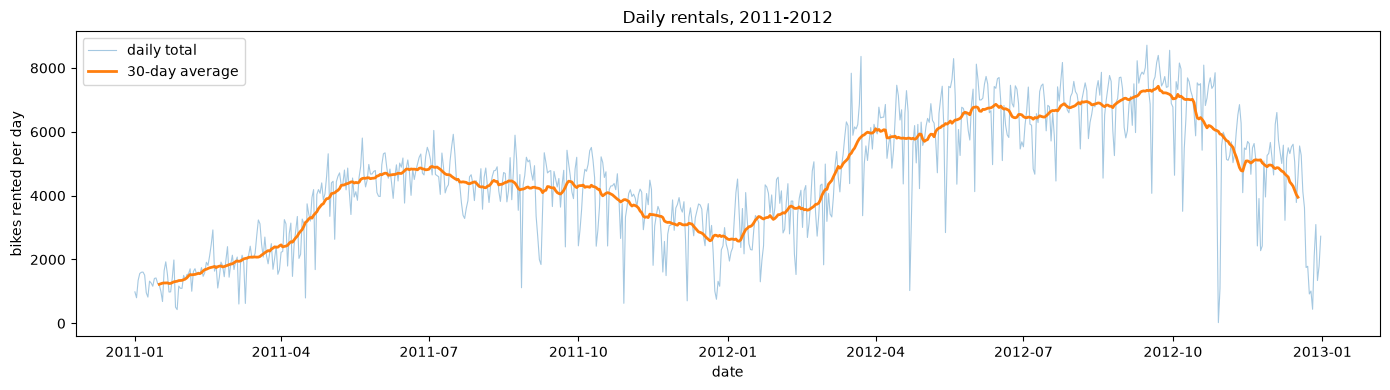

In [5]:
# total rentals per day over the whole two years
daily = df.groupby(pd.to_datetime(df['dteday']))['cnt'].sum()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily.index, daily.values, linewidth=0.8, alpha=0.4, label='daily total')
ax.plot(daily.index, daily.rolling(30, center=True).mean(), linewidth=2, label='30-day average')
ax.set(xlabel='date', ylabel='bikes rented per day', title='Daily rentals, 2011-2012')
ax.legend()
plt.tight_layout()
plt.show()

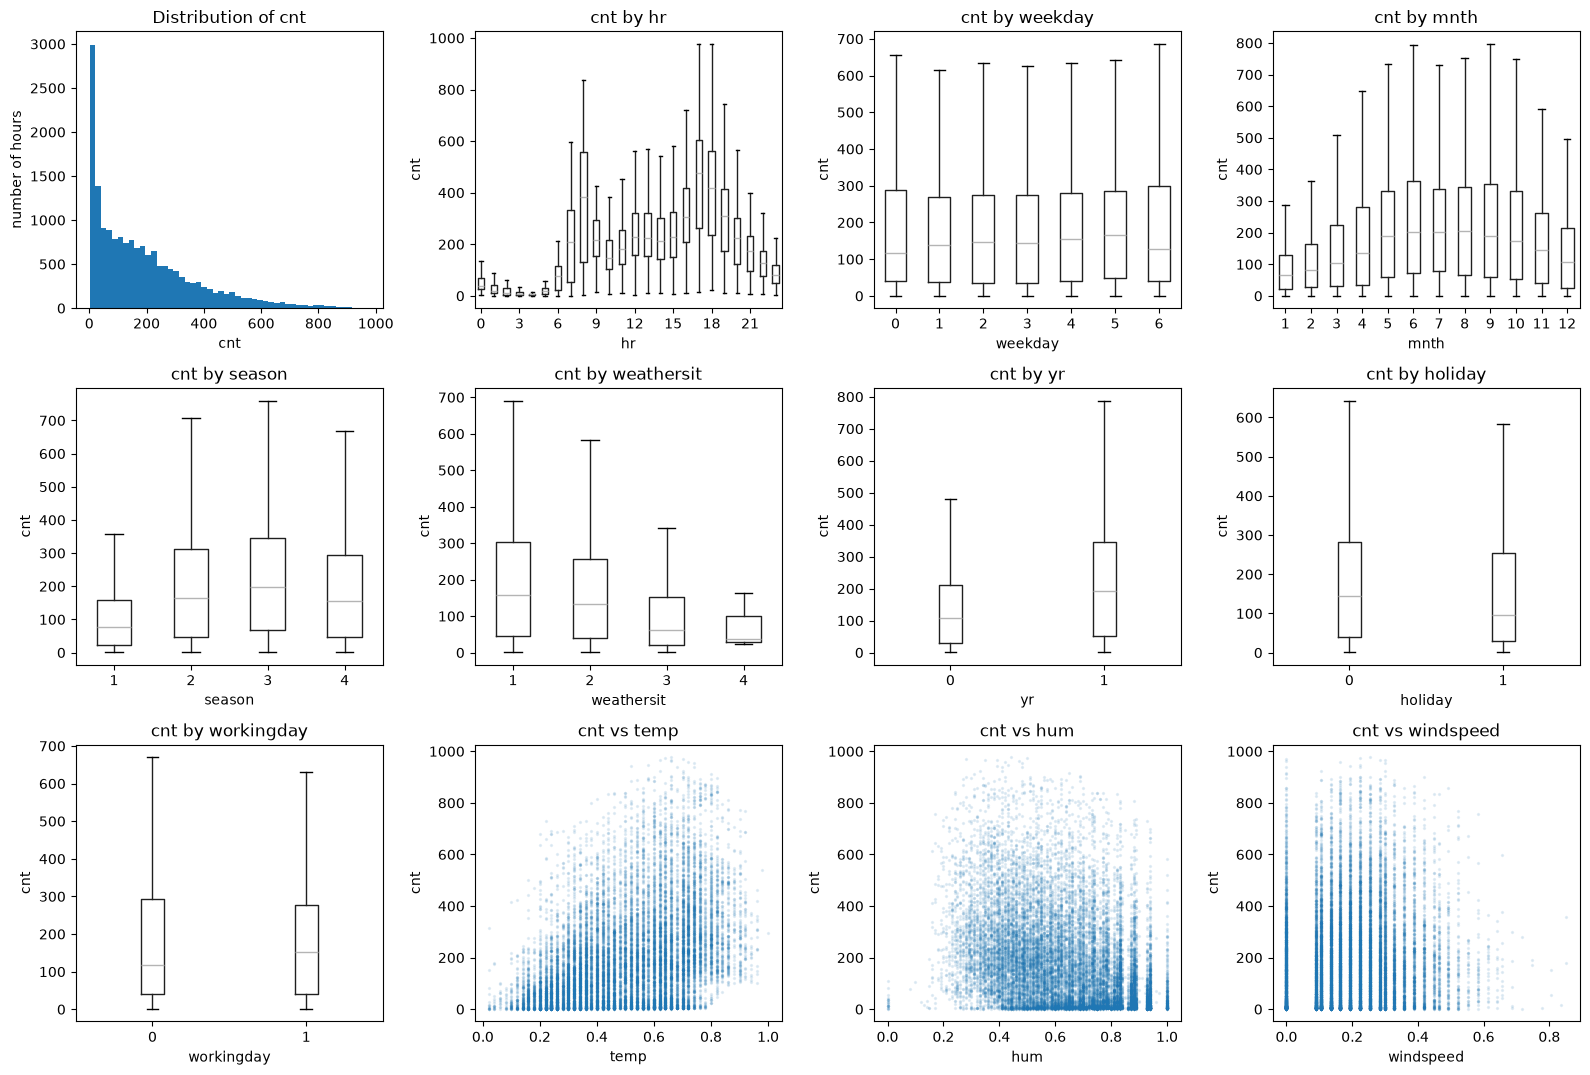

skewness of cnt: 1.28


In [6]:
# rentals against every feature
categorical = ['hr', 'weekday', 'mnth', 'season', 'weathersit', 'yr', 'holiday', 'workingday']
continuous = ['temp', 'hum', 'windspeed']

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

# distribution of the target
axes[0].hist(df['cnt'], bins=50)
axes[0].set(title='Distribution of cnt', xlabel='cnt', ylabel='number of hours')

# categorical features: one box per category
for ax, col in zip(axes[1:9], categorical):
    df.boxplot(column='cnt', by=col, ax=ax, grid=False, showfliers=False)
    ax.set(title=f'cnt by {col}', xlabel=col, ylabel='cnt')
axes[1].set_xticks(range(1, 25, 3), range(0, 24, 3))  # thin out the 24 hour labels

# continuous features: every hour as a dot
for ax, col in zip(axes[9:], continuous):
    ax.scatter(df[col], df['cnt'], s=2, alpha=0.1)
    ax.set(title=f'cnt vs {col}', xlabel=col, ylabel='cnt')

fig.suptitle('')  # remove pandas' automatic "grouped by" title
plt.tight_layout()
plt.show()

print('skewness of cnt:', round(df['cnt'].skew(), 2))

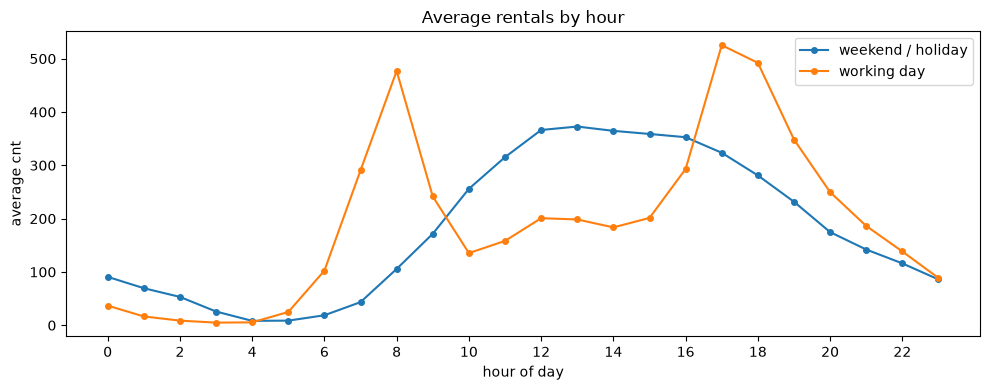

,weekend / holiday,working day
hr,,
8,106.0,477.0
12,366.0,201.0
17,324.0,525.0


In [7]:
# average rentals by hour, split by working day vs weekend/holiday
hourly = df.groupby(['hr', 'workingday'])['cnt'].mean().unstack()
hourly.columns = ['weekend / holiday', 'working day']

fig, ax = plt.subplots(figsize=(10, 4))
hourly.plot(ax=ax, marker='o', markersize=4)
ax.set(xlabel='hour of day', ylabel='average cnt', title='Average rentals by hour')
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

hourly.loc[[8, 12, 17]].round(0)

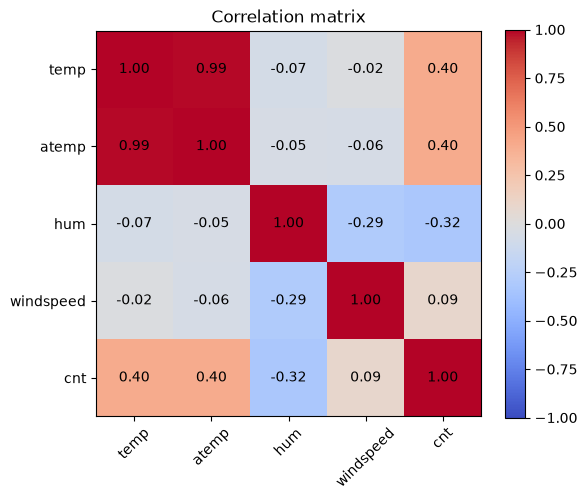

In [8]:
# correlation between the continuous variables and the target
corr = df[['temp', 'atemp', 'hum', 'windspeed', 'cnt']].corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
fig.colorbar(im)
ax.set_title('Correlation matrix')
plt.tight_layout()
plt.show()

### Observations

1. **Data quality:** there are no missing values or duplicate rows, but a few things need fixing in Part 3:
   - `hum` has a minimum of 0.0, which is impossible for humidity.
   - `windspeed` has many readings of exactly 0.
   - `weathersit` 4 (heavy rain) appears only 3 times.
   - `dteday` is stored as text.
2. **Trend and seasonality:** daily rentals follow a yearly cycle, high in summer and low in winter, and 2012 is much busier than 2011. So `yr`, `season` and `mnth` should all matter.
3. **Skewed target:** most hours have fewer than 200 rentals, with a long tail up to 977 (skewness 1.28). This motivates the log transform used for the sinusoidal model in Part 6.
4. **The hour is the strongest pattern, and it depends on the type of day:**
   - Working days have two commute peaks: 477 bikes on average at 8:00 and 525 at 17:00.
   - Weekends and holidays have one midday hump: 366 at 12:00, against 201 on working days.

   This is an **interaction** between `hr` and `workingday`: the effect of the hour depends on the type of day. A linear model adds up the effect of each feature separately, so it can't represent this.
5. **The relationship with the hour is not linear,** so a straight line `w * hr` can't follow two peaks. The hour and month are also cyclical: 23:00 and 0:00 are neighbours but numerically far apart, and so are December (12) and January (1).
6. **Weather:**
   - `temp` has the strongest correlation with `cnt` (0.40), and `hum` is negatively correlated (-0.32).
   - `windspeed` is barely correlated (0.09).
   - Rentals fall as `weathersit` gets worse.
   - `temp` and `atemp` are almost identical (correlation 0.99).
7. **`weekday` and `workingday` look unimportant in the box plots,** but that's misleading. Working days and weekends peak at different hours, so the daily totals even out. The difference only shows when you look at the hours (point 4).

## Part 3: Data preparation

| Issue | Evidence | Decision | Reason |
| --- | --- | --- | --- |
| `dteday` is text | dtype `str` | Convert to datetime | Needed for the time plots and the time-based split. Not used as a model input, because `yr`, `mnth`, `weekday` and `hr` already contain the same information |
| Impossible humidity | 22 hours with `hum` = 0, all on 2011-03-10 | Treat as missing and interpolate from the neighbouring hours | The whole day is missing, so there's no same-day average to use. Humidity changes smoothly, so interpolation is reasonable |
| Rare weather category | `weathersit` 4 has only 3 hours | Merge into 3 (heavy rain into light rain) | Too few examples to learn from, and both are bad weather |
| Redundant feature | `temp` and `atemp` correlation 0.988; condition number of $X^TX$ is 216.8 with `atemp` and 12.9 without | Drop `atemp` | Two near-identical columns make the feature matrix almost rank-deficient, so $X^TX$ is close to singular and the normal equation $\mathbf{w} = (X^TX)^{-1}X^T\mathbf{y}$ becomes unstable. The weights of the two columns can then trade off against each other (multicollinearity). Dropping one loses almost no information |
| Zero wind speed | 2,180 hours (12.5%) are exactly 0; the next smallest value is 0.0896 | Keep as is | The gap suggests low wind is recorded as 0, but real calm can't be told apart from a missing reading. Filling in 1 in 8 rows would invent data, and `windspeed` turns out to be one of the least important features (Parts 5 and 6) |
| Missing hours | 17,544 hours expected, 17,379 present (165 missing) | Keep as is | Each hour is predicted from its own features, with no values from previous hours, so gaps in the timeline don't affect training |
| Leakage | `casual` + `registered` = `cnt` | Exclude | Using them would give the model the answer |

**Feature scaling:**

- Gradient descent (Part 4) and the polynomial and Ridge models (Parts 5 and 6) use **standardized features** (mean 0, standard deviation 1). For gradient descent this lets one learning rate suit every weight. For Ridge, the penalty on $\sum w_j^2$ is only fair if all features are on the same scale.
- The scaler is always **fit on the training data only**, so no information from the validation or test set leaks into training.
- The plain linear regression and the tree models use the raw features. Least squares gives the same predictions with or without scaling, and trees split on thresholds, so scale makes no difference to them.

**Training / validation / test split:**

- **Test set (20%):** set aside with `random_state=42` and only used to report final results.
- **Validation set (25% of the remaining 80%, so 20% overall):** used to choose hyperparameters (polynomial degree, λ, number of sine/cosine pairs). Choosing them on the test set would make the test score optimistic.
- **Training set (60%):** used to fit the model for each candidate hyperparameter. After a hyperparameter is chosen, the final model is refit on the full 80% (training + validation).
- The random split assumes the hours are **i.i.d.** (independent and identically distributed). Neighbouring hours are in fact strongly related, so Part 7 checks the results with a time-based split.

In [9]:
# 1. Convert the date column from text to a real date
df['dteday'] = pd.to_datetime(df['dteday'])
print('dteday dtype:', df['dteday'].dtype)

# 2. Fix impossible humidity values (0%)
# all 22 zero readings are on 2011-03-10, so there is no same-day average to use;
# interpolate from the neighbouring hours instead (rows are already in time order)
print('hum == 0 before:', (df['hum'] == 0).sum(), df.loc[df['hum'] == 0, 'dteday'].dt.date.unique())
df['hum'] = df['hum'].replace(0, np.nan).interpolate()
print('hum == 0 after:', (df['hum'] == 0).sum(), '| hum NaN after:', df['hum'].isna().sum())

# 3. Merge the very rare weather type 4 (3 rows) into type 3
print('weathersit before:', df['weathersit'].value_counts().to_dict())
df['weathersit'] = df['weathersit'].replace(4, 3)
print('weathersit after:', df['weathersit'].value_counts().to_dict())

# 4. Drop atemp: it's almost identical to temp (corr 0.988)
# near-duplicate columns make X^T X close to singular, so the normal equation becomes unstable;
# the condition number of X^T X (standardized features) measures this: large = close to singular
features = df.drop(columns=['dteday', 'cnt'])
for name, cols in [('with atemp', features), ('without atemp', features.drop(columns=['atemp']))]:
    Z = (cols - cols.mean()) / cols.std()
    print(f'condition number of X^T X {name}: {np.linalg.cond(Z.T @ Z):.1f}')
print('temp/atemp corr:', round(df['temp'].corr(df['atemp']), 3))
df = df.drop(columns=['atemp'])

# 5. Readable labels for plotting (optional)
df['season_name'] = df['season'].map({1: 'winter', 2: 'spring', 3: 'summer', 4: 'fall'})
print('unmapped seasons:', df['season_name'].isna().sum())

# 6. Check the hours missing from the timeline
expected_hours = df['dteday'].nunique() * 24
print('expected hours:', expected_hours, '| rows:', len(df), '| missing:', expected_hours - len(df))

# preview
df.head()

dteday dtype: datetime64[us]
hum == 0 before: 22 [datetime.date(2011, 3, 10)]
hum == 0 after: 0 | hum NaN after: 0
weathersit before: {1: 11413, 2: 4544, 3: 1419, 4: 3}
weathersit after: {1: 11413, 2: 4544, 3: 1422}
condition number of X^T X with atemp: 216.8
condition number of X^T X without atemp: 12.9
temp/atemp corr: 0.988
unmapped seasons: 0
expected hours: 17544 | rows: 17379 | missing: 165


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,hum,windspeed,cnt,season_name
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.81,0.0,16,winter
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.80,0.0,40,winter
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.80,0.0,32,winter
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.75,0.0,13,winter
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.75,0.0,1,winter


In [10]:
# windspeed: many hours are recorded as exactly 0
print('windspeed == 0:', (df['windspeed'] == 0).sum(), f"hours ({(df['windspeed'] == 0).mean():.1%})")
print('smallest non-zero values:', np.sort(df.loc[df['windspeed'] > 0, 'windspeed'].unique())[:3].round(4))

windspeed == 0: 2180 hours (12.5%)
smallest non-zero values: [0.0896 0.1045 0.1343]


In [11]:
# prepare features and target for regression
# dteday is covered by yr/mnth/weekday/hr, and season_name is only for plotting
X = df.drop(columns=['cnt', 'dteday', 'season_name'])
y = df['cnt']

# split data into training and test sets (80/20); the test set is only used to report final results
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# hold out 25% of the training set as a validation set (60/20/20 overall) for choosing hyperparameters
# (polynomial degree, regularization strength, number of sine/cosine pairs) without touching the test set
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42)

print('training (fit):', X_tr.shape, '| validation:', X_val.shape, '| test:', X_test.shape)
print('full training set (fit + validation):', X_train.shape)
print('features:', list(X.columns))

training (fit): (10427, 11) | validation: (3476, 11) | test: (3476, 11)
full training set (fit + validation): (13903, 11)
features: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed']


## Part 4: Initial model, multiple linear regression

### Why this approach

Linear regression is the natural baseline. It's the simplest regression model, it's fast and interpretable, and its score sets the level every later model has to beat. The model, or hypothesis, is

$$\hat{y} = h(\mathbf{x}) = w_1x_1 + w_2x_2 + \dots + w_{11}x_{11} + b = \mathbf{w}^T\mathbf{x}$$

with 11 weights and a bias as its learned **parameters**. Written for all $N$ examples at once (vectorized), the predictions are $\hat{\mathbf{y}} = X\mathbf{w}$.

The parameters minimize the cost $J(\mathbf{w})$ from Part 1. There are two ways to find them:

- **Direct solution (normal equation):** set $\partial J / \partial \mathbf{w} = 0$, which gives $\mathbf{w} = (X^TX)^{-1}X^T\mathbf{y}$. `LinearRegression` does this.
- **Gradient descent:** start from $\mathbf{w} = 0$ and repeat $\mathbf{w} \leftarrow \mathbf{w} - \alpha\,\partial J/\partial \mathbf{w}$, where $\partial J/\partial \mathbf{w} = \frac{1}{N}X^T(\hat{\mathbf{y}} - \mathbf{y})$ and $\alpha$ is the learning rate. The second cell implements this to show the cost falling, and to check it reaches the same solution.

The code features (`hr`, `season`, `weathersit`, ...) are fed in as plain numbers. Part 2 already suggests this will underfit, which the results below confirm.

In [12]:
# initial model: multiple linear regression, y_hat = w1*x1 + ... + w11*x11 + b
# LinearRegression finds the weights directly with the normal equation w = (X^T X)^-1 X^T y
lin = LinearRegression()
lin.fit(X_train, y_train)

# check predictions scores
lin_pred = lin.predict(X_test)
lin_train_pred = lin.predict(X_train)

print(f'MSE  {mean_squared_error(y_test, lin_pred):.1f}')
print(f'RMSE {mean_squared_error(y_test, lin_pred) ** 0.5:.1f}')
print(f'MAE  {mean_absolute_error(y_test, lin_pred):.1f}')
print(f'R2   {r2_score(y_test, lin_pred):.3f}')

# training scores, to compare with the test scores for signs of over- or underfitting
print(f'train RMSE {mean_squared_error(y_train, lin_train_pred) ** 0.5:.1f} | train R2 {r2_score(y_train, lin_train_pred):.3f}')
print('negative predictions:', (lin_pred < 0).sum())

MSE  19405.9
RMSE 139.3
MAE  104.8
R2   0.387
train RMSE 142.4 | train R2 0.389
negative predictions: 158


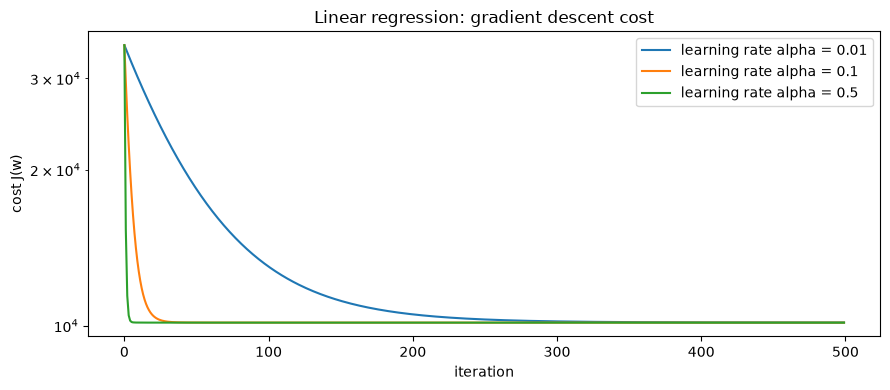

largest difference between gradient-descent and normal-equation weights: 0.0025
gradient descent test RMSE: 139.3


In [13]:
# the same model trained with batch gradient descent, to watch the cost J(w) fall at every iteration
# features are standardized first so one learning rate suits every weight (scaler fit on training data only)
scaler = StandardScaler().fit(X_train)
Xs_train = np.c_[np.ones(len(X_train)), scaler.transform(X_train)]   # column of ones: w0 is the bias b
Xs_test = np.c_[np.ones(len(X_test)), scaler.transform(X_test)]
y_vec = y_train.to_numpy()
N = len(y_vec)

fig, ax = plt.subplots(figsize=(9, 4))
for alpha in [0.01, 0.1, 0.5]:
    w = np.zeros(Xs_train.shape[1])
    costs = []
    for _ in range(500):
        y_hat = Xs_train @ w                                    # vectorized prediction, y_hat = Xw
        costs.append(np.sum((y_vec - y_hat) ** 2) / (2 * N))    # J(w) = 1/2N * sum (y - y_hat)^2
        w = w - alpha * Xs_train.T @ (y_hat - y_vec) / N         # w <- w - alpha * dJ/dw
    ax.plot(costs, label=f'learning rate alpha = {alpha}')
    if alpha == 0.1:
        w_gd = w
ax.set(xlabel='iteration', ylabel='cost J(w)', yscale='log', title='Linear regression: gradient descent cost')
ax.legend()
plt.tight_layout()
plt.show()

# compare with the direct (normal equation) solution on the same standardized features
w_normal = np.linalg.solve(Xs_train.T @ Xs_train, Xs_train.T @ y_vec)
print('largest difference between gradient-descent and normal-equation weights:', round(np.abs(w_gd - w_normal).max(), 4))
print(f'gradient descent test RMSE: {mean_squared_error(y_test, Xs_test @ w_gd) ** 0.5:.1f}')

**Gradient descent:**

- With **α = 0.1** the cost $J(\mathbf{w})$ falls from 34,761 to its minimum of 10,136.1 within about 50 iterations. The weights end within 0.0025 of the normal-equation solution, with the same test RMSE (139.3). The two methods find the same minimum, as expected for a convex quadratic cost.
- **α = 0.5** gets there in about 10 iterations, and is still stable.
- **α = 0.01** is too small: after 500 iterations the cost is 10,139.4 and some weights are still 3.6 away from the solution.
- The learning rate is a **hyperparameter**: too small converges slowly, too large overshoots and diverges. The direct solution is fine here because there are only 12 parameters. Gradient descent matters for models with no closed-form solution, and for very large numbers of features.

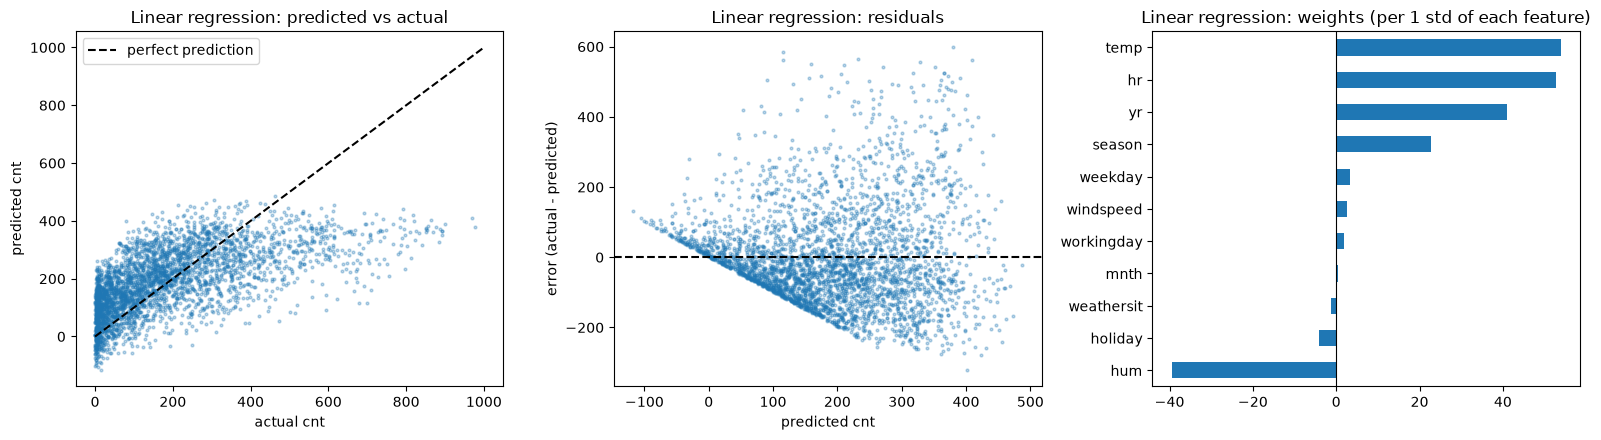

In [14]:
# plot scores
# predicted vs actual counts of bikes used
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(y_test, lin_pred, s=4, alpha=0.3)
axes[0].plot([0, 1000], [0, 1000], 'k--', label='perfect prediction')
axes[0].set(xlabel='actual cnt', ylabel='predicted cnt', title='Linear regression: predicted vs actual')
axes[0].legend()

# residuals (errors)
lin_residuals = y_test - lin_pred
axes[1].scatter(lin_pred, lin_residuals, s=4, alpha=0.3)
axes[1].axhline(0, color='k', linestyle='--')
axes[1].set(xlabel='predicted cnt', ylabel='error (actual - predicted)', title='Linear regression: residuals')

# what the model learned: weights on standardized features, so they are comparable
coefs = pd.Series(w_normal[1:], index=X.columns).sort_values()
coefs.plot.barh(ax=axes[2], title='Linear regression: weights (per 1 std of each feature)')
axes[2].axvline(0, color='k', linewidth=0.8)

plt.tight_layout()
plt.show()

### Results

| | RMSE | MAE | R² |
| --- | --- | --- | --- |
| Test | 139.3 | 104.8 | 0.387 |
| Train | 142.4 | | 0.389 |

- The baseline explains only 39% of the variance, with an average error of 105 bikes when the average hour has 189.
- **Training and test errors are almost identical,** both high. Following the lecture's diagnosis table (train error high, validation error high), this is **underfitting**: the model is too simple for the pattern (**high bias**).
- **Predicted vs actual:** predictions never go above 487 even though up to 977 bikes were rented, so the model can't reach the busy hours. 158 test hours get a negative prediction, which is impossible for a count.
- **Residuals:** the errors fan out as predictions grow, and 424 test hours are off by more than 200 bikes.
- **Weights (per standard deviation of each feature):**
  - `temp` (+53.8) and `hr` (+52.8) have the largest effect, followed by `yr` (+41.0, since 2012 was busier) and `season` (+22.7). `hum` (−39.5) reduces rentals.
  - `hr` gets one positive weight, so the model says "later in the day means more bikes". It can't express two peaks, and it over-predicts late evenings.
  - `weathersit`, `mnth` and `workingday` get weights close to 0. That's not because they don't matter: a single straight-line weight can't capture their effect, such as the commute peaks that only happen on working days.

The baseline underfits. The fix suggested in the lectures is a more flexible model or better features, explored in Parts 5 and 6.

## Part 5: Model complexity and generalization

**Model complexity** is how flexible the function a model can fit is. It's linked to **generalization**, the ability to predict well on unseen data:

- **Too little complexity (underfitting, high bias):** the model can't represent the pattern. Training and validation error are both high, and close together.
- **Too much complexity (overfitting, high variance):** the model fits noise in the training data. Training error is low, but validation error is much higher.
- **The bias-variance tradeoff:** increasing complexity typically reduces bias and increases variance. The best model is in between.

Three experiments:

1. **Polynomial degree M:** make the linear model more complex by adding polynomial features (the feature map $\Psi(X)$ from Lecture 7).
2. **Learning curve** of the linear baseline: error against the amount of training data.
3. **A different, more flexible model family,** the random forest, with the maximum tree depth varied.

### Experiment 1: polynomial degree

Degree M adds every product of the features up to total degree M; for example, degree 2 adds $x_1^2$, $x_1x_2$, and so on. The result is still linear regression on the new features $\Psi(X)$, so everything from Part 4 still applies. Each model is fit on the training set and scored on the validation set.

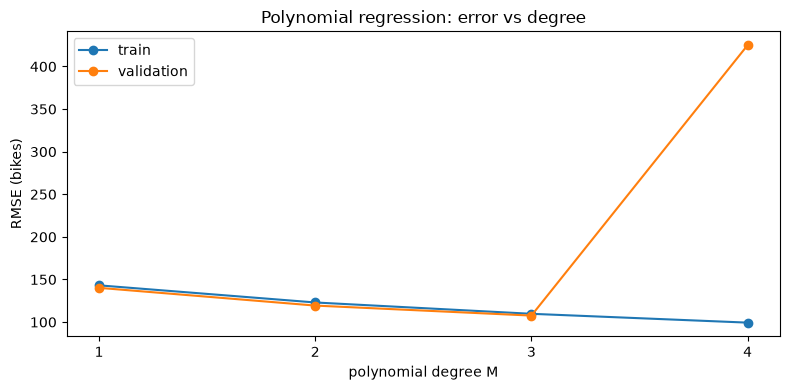

,columns,train RMSE,validation RMSE,largest |w|
degree M,,,,
1,11,143.1,140.2,53.3
2,77,123.0,119.4,63.5
3,363,109.7,107.6,112.5
4,1364,99.4,425.0,3207.2


In [15]:
# complexity experiment 1: polynomial degree M
# degree M adds every product of the features up to total degree M, then fits ordinary linear regression;
# fit on the training part, score on the validation set
degree_rows = []
for M in [1, 2, 3, 4]:
    poly_model = make_pipeline(StandardScaler(), PolynomialFeatures(M, include_bias=False),
                               StandardScaler(), LinearRegression())
    poly_model.fit(X_tr, y_tr)
    degree_rows.append({
        'degree M': M,
        'columns': poly_model[1].n_output_features_,
        'train RMSE': mean_squared_error(y_tr, poly_model.predict(X_tr)) ** 0.5,
        'validation RMSE': mean_squared_error(y_val, poly_model.predict(X_val)) ** 0.5,
        'largest |w|': np.abs(poly_model[-1].coef_).max(),
    })
degree_results = pd.DataFrame(degree_rows).set_index('degree M')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(degree_results.index, degree_results['train RMSE'], marker='o', label='train')
ax.plot(degree_results.index, degree_results['validation RMSE'], marker='o', label='validation')
ax.set(xlabel='polynomial degree M', ylabel='RMSE (bikes)', xticks=[1, 2, 3, 4],
       title='Polynomial regression: error vs degree')
ax.legend()
plt.tight_layout()
plt.show()

degree_results.round(1)

**Results:**

| M | Columns | Train RMSE | Validation RMSE | Largest \|w\| |
| --- | --- | --- | --- | --- |
| 1 | 11 | 143.1 | 140.2 | 53 |
| 2 | 77 | 123.0 | 119.4 | 64 |
| 3 | 363 | 109.7 | 107.6 | 113 |
| 4 | 1,364 | 99.4 | **425.0** | **3,207** |

- **M = 1 to 3:** both errors fall together, so extra complexity reduces bias. The model is still underfitting.
- **M = 4: overfitting.** Training error keeps falling (99.4), but validation error jumps to 425, worse than the baseline. This is the same pattern as the M = 9 example in Lecture 7: with 1,364 columns, the model fits noise in the training data.
- **The weights explode,** from at most 113 at M = 3 to 3,207 at M = 4. As in Lecture 8, very large coefficients mean a small change in x causes a large change in $\hat{y}$, and the model becomes unstable. Part 6 uses regularization to fix this.
- Degree 3 gives the lowest validation error here, but it still underfits (train and validation errors close, both above 100).

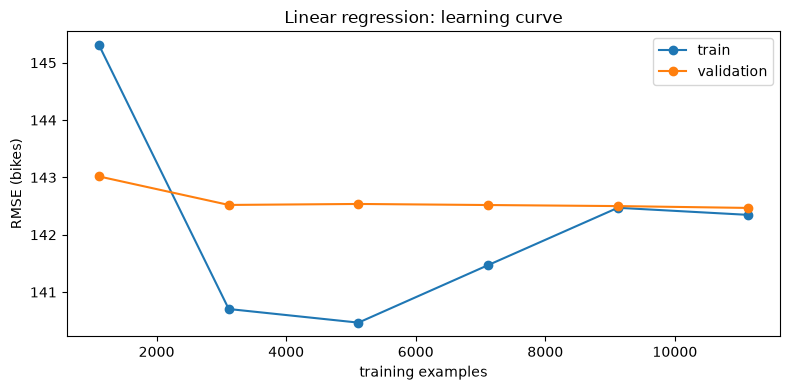

final train RMSE: 142.3 | final validation RMSE: 142.5


In [16]:
# experiment 2: learning curve for the linear baseline, error vs amount of training data (5-fold CV)
sizes, lc_train, lc_val = learning_curve(
    LinearRegression(), X_train, y_train, cv=5,
    train_sizes=np.linspace(0.1, 1.0, 6), scoring='neg_root_mean_squared_error')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sizes, -lc_train.mean(axis=1), marker='o', label='train')
ax.plot(sizes, -lc_val.mean(axis=1), marker='o', label='validation')
ax.set(xlabel='training examples', ylabel='RMSE (bikes)', title='Linear regression: learning curve')
ax.legend()
plt.tight_layout()
plt.show()

print('final train RMSE:', round(-lc_train.mean(axis=1)[-1], 1), '| final validation RMSE:', round(-lc_val.mean(axis=1)[-1], 1))

### Experiment 2: learning curve

- From about 1,100 to 11,100 training examples, training and validation RMSE stay around 142, and they converge (142.3 and 142.5).
- A learning curve where both errors plateau close together at a high level is the classic sign of **high bias**: as in the Lecture 8 discussion, adding more data doesn't help. The model needs more complexity or better features.

### Experiment 3: a more flexible model family, the random forest

A random forest is an **ensemble** of decision trees built with **bagging**: each tree is trained on a bootstrap sample of the training rows (drawn randomly with replacement), and the trees' predictions are averaged.

Each tree splits the data on thresholds, such as `hr` ≤ 7.5, so it can:

- follow any shape, including the two commute peaks;
- learn interactions automatically, for example by splitting on `workingday` and then on `hr`;
- work without scaling or encoding.

The model uses 200 trees, grown to full depth (the default).

In [17]:
# initialize and fit the random forest model
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)   # unscaled is fine for a random forest

# check predictions scores
rf_pred = rf.predict(X_test)
rf_train_pred = rf.predict(X_train)

print(f'MSE  {mean_squared_error(y_test, rf_pred):.1f}')
print(f'RMSE {mean_squared_error(y_test, rf_pred) ** 0.5:.1f}')
print(f'MAE  {mean_absolute_error(y_test, rf_pred):.1f}')
print(f'R2   {r2_score(y_test, rf_pred):.3f}')

# training scores, to compare with the test scores for signs of over- or underfitting
print(f'train RMSE {mean_squared_error(y_train, rf_train_pred) ** 0.5:.1f} | train R2 {r2_score(y_train, rf_train_pred):.3f}')

MSE  1763.1
RMSE 42.0
MAE  24.6
R2   0.944
train RMSE 15.9 | train R2 0.992


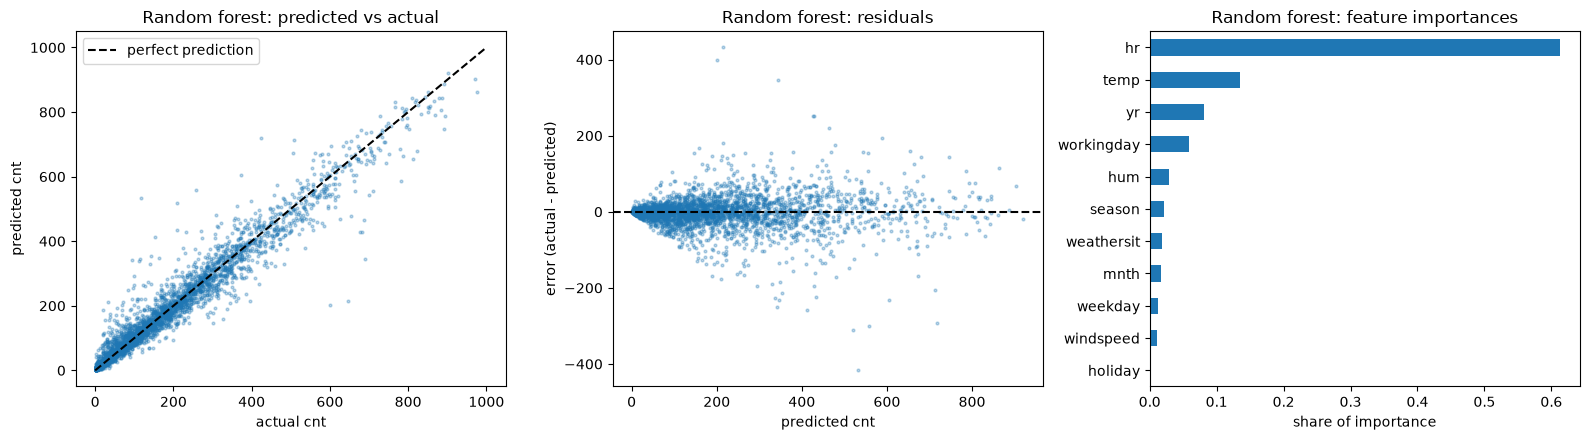

In [18]:
# plot scores
# predicted vs actual counts of bikes used
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(y_test, rf_pred, s=4, alpha=0.3)
axes[0].plot([0, 1000], [0, 1000], 'k--', label='perfect prediction')
axes[0].set(xlabel='actual cnt', ylabel='predicted cnt', title='Random forest: predicted vs actual')
axes[0].legend()

# residuals (errors)
rf_residuals = y_test - rf_pred
axes[1].scatter(rf_pred, rf_residuals, s=4, alpha=0.3)
axes[1].axhline(0, color='k', linestyle='--')
axes[1].set(xlabel='predicted cnt', ylabel='error (actual - predicted)', title='Random forest: residuals')

# what the model learned (importances are always positive and sum to 1)
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importances.plot.barh(ax=axes[2], title='Random forest: feature importances')
axes[2].set_xlabel('share of importance')

plt.tight_layout()
plt.show()

**Results:**

- **Test:** RMSE 42.0, MAE 24.6, R² 0.944. The error is less than a third of the baseline's (139.3).
- **Train:** RMSE 15.9, R² 0.992. The large gap between train and test means the trees **overfit**: they largely memorize the training data. Even so, the test error is far better than the baseline's.
- The predicted-vs-actual points follow the diagonal up to the busiest hours, and the residuals are centred on 0. Only 18 test hours are off by more than 200 bikes, against 424 for the baseline.
- **Importances:** `hr` 0.61, `temp` 0.14, `yr` 0.08 and `workingday` 0.06. `windspeed` is only 0.01, which supports leaving its zero readings as they are (Part 3).

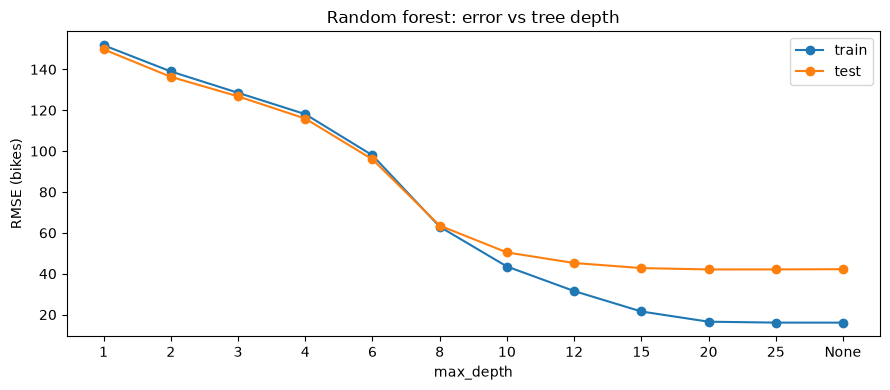

max_depth,1,2,3,4,6,8,10,12,15,20,25,None
train RMSE,151.8,139.0,128.5,118.1,97.9,63.0,43.5,31.5,21.5,16.5,16.1,16.1
test RMSE,149.8,136.3,126.8,115.9,96.0,63.5,50.4,45.3,42.8,42.1,42.1,42.2
gap,-2.0,-2.6,-1.7,-2.2,-2.0,0.5,6.9,13.7,21.2,25.6,26.0,26.2


In [19]:
# complexity experiment 2: maximum depth of the random forest's trees
# deeper trees = more splits = more flexible model (None = grow until leaves are pure)
depths = [1, 2, 3, 4, 6, 8, 10, 12, 15, 20, 25, None]
d_train_rmse, d_test_rmse = [], []
for depth in depths:
    m = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    m.fit(X_train, y_train)
    d_train_rmse.append(mean_squared_error(y_train, m.predict(X_train)) ** 0.5)
    d_test_rmse.append(mean_squared_error(y_test, m.predict(X_test)) ** 0.5)

labels = [str(d) for d in depths]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(labels, d_train_rmse, marker='o', label='train')
ax.plot(labels, d_test_rmse, marker='o', label='test')
ax.set(xlabel='max_depth', ylabel='RMSE (bikes)', title='Random forest: error vs tree depth')
ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({'max_depth': labels, 'train RMSE': d_train_rmse, 'test RMSE': d_test_rmse,
              'gap': np.array(d_test_rmse) - np.array(d_train_rmse)}).round(1).set_index('max_depth').T

**Tree depth experiment:**

- **Depth 1-6:** training and test error are almost equal and high (from about 150 down to about 97). The model is **underfitting**.
- **Depth 8:** the best balance between the two (63.0 train, 63.5 test).
- **Depth 10 and above:** training error keeps falling, to 16.1, while test error levels off at about 42. The gap grows to 26 bikes. The model is **overfitting**.
- **Test error doesn't rise again, though,** unlike the polynomial model. Averaging 100 trees trained on different bootstrap samples cancels much of each individual tree's variance, so a forest of deep trees still generalizes well. That's why random forests grow full-depth trees by default.

The depth controls the **bias-variance tradeoff**: shallow trees have high bias, and deep trees have high variance that the averaging partly offsets.

## Part 6: Improving the model

Part 5 found three problems:

- The linear baseline **underfits** (high bias).
- Making it more complex with polynomial features **overfits** at degree 4 (high variance, exploding weights).
- The random forest fits well but **overfits**, with a 26-bike gap between training and test error.

Four approaches, following the Lecture 8 and 9 remedies:

1. **Regularization (Ridge)** to control the overfitting degree-4 model.
2. **Feature engineering** (sinusoidal features) to fix the baseline's underfitting.
3. **Gradient boosting with early stopping,** a different ensemble with built-in regularization.
4. **Hyperparameter tuning with cross-validation.**

### 6.1 Regularization: Ridge regression

Rather than cutting the model back to fewer features, regularization keeps the complex model but penalizes large weights. L2 regularization (**Ridge regression**) adds the squared L2 norm of the weights to the cost:

$$J(\mathbf{w}) = \frac{1}{2N}\sum_{i=1}^{N}\left(y^{(i)} - \hat{y}^{(i)}\right)^2 + \frac{\lambda}{2N}\sum_{j} w_j^2$$

- **λ = 0** gives the original, overfitting model; a very large **λ** pushes every weight towards 0, so the model underfits.
- λ is a **hyperparameter**: it's set before training rather than learned. Following Lecture 9, candidates are tried in powers of ten, each model is scored on the **validation set**, and the one with the lowest validation error is kept. The test set is never used for this choice.
- L1 (Lasso) would also set some weights exactly to zero (feature selection). L2 is used here because the goal is to shrink 1,364 correlated polynomial terms smoothly rather than pick a few.

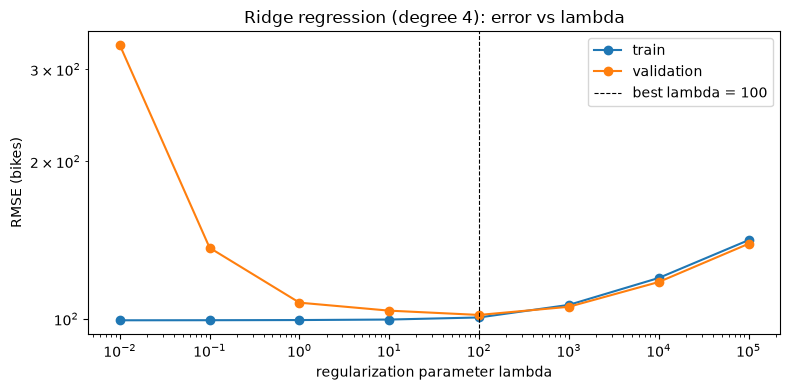

MSE  10452.4
RMSE 102.2
MAE  71.9
R2   0.670
train RMSE 99.9 | train R2 0.699


,train RMSE,validation RMSE,largest |w|
lambda,,,
0.01,99.4,333.6,609.4
0.10,99.4,136.7,253.1
1.00,99.5,107.4,125.9
10.00,99.7,103.7,123.8
100.00,100.6,101.7,104.9
1000.00,106.3,105.5,45.9
10000.00,119.7,117.6,11.7
100000.00,141.4,139.1,4.1


In [20]:
# improvement 1: L2 regularization (Ridge regression) on the overfitting degree-4 model
# J(w) = 1/2N * sum (y - y_hat)^2 + lambda/2N * sum w_j^2   (scikit-learn calls lambda 'alpha')
# lambda is a hyperparameter: try powers of ten and keep the one with the lowest validation error
lambdas = [0.01, 0.1, 1, 10, 100, 1000, 10000, 100000]
ridge_rows = []
for lam in lambdas:
    ridge_model = make_pipeline(StandardScaler(), PolynomialFeatures(4, include_bias=False),
                                StandardScaler(), Ridge(alpha=lam))
    ridge_model.fit(X_tr, y_tr)
    ridge_rows.append({
        'lambda': lam,
        'train RMSE': mean_squared_error(y_tr, ridge_model.predict(X_tr)) ** 0.5,
        'validation RMSE': mean_squared_error(y_val, ridge_model.predict(X_val)) ** 0.5,
        'largest |w|': np.abs(ridge_model[-1].coef_).max(),
    })
ridge_results = pd.DataFrame(ridge_rows).set_index('lambda')
best_lambda = ridge_results['validation RMSE'].idxmin()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ridge_results.index, ridge_results['train RMSE'], marker='o', label='train')
ax.plot(ridge_results.index, ridge_results['validation RMSE'], marker='o', label='validation')
ax.axvline(best_lambda, color='k', linestyle='--', linewidth=0.8, label=f'best lambda = {best_lambda:g}')
ax.set(xlabel='regularization parameter lambda', ylabel='RMSE (bikes)', xscale='log', yscale='log',
       title='Ridge regression (degree 4): error vs lambda')
ax.legend()
plt.tight_layout()
plt.show()

# refit with the chosen lambda on the full training set, then evaluate once on the test set
ridge = make_pipeline(StandardScaler(), PolynomialFeatures(4, include_bias=False),
                      StandardScaler(), Ridge(alpha=best_lambda))
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)
ridge_train_pred = ridge.predict(X_train)

print(f'MSE  {mean_squared_error(y_test, ridge_pred):.1f}')
print(f'RMSE {mean_squared_error(y_test, ridge_pred) ** 0.5:.1f}')
print(f'MAE  {mean_absolute_error(y_test, ridge_pred):.1f}')
print(f'R2   {r2_score(y_test, ridge_pred):.3f}')
print(f'train RMSE {mean_squared_error(y_train, ridge_train_pred) ** 0.5:.1f} | train R2 {r2_score(y_train, ridge_train_pred):.3f}')

ridge_results.round(1)

**Results:**

| λ | Train RMSE | Validation RMSE | Largest \|w\| |
| --- | --- | --- | --- |
| 0 (no regularization) | 99.4 | 425.0 | 3,207 |
| 0.01 | 99.4 | 333.6 | 609 |
| 1 | 99.5 | 107.4 | 126 |
| **100** | **100.6** | **101.7** | **105** |
| 10,000 | 119.7 | 117.6 | 12 |
| 100,000 | 141.4 | 139.1 | 4 |

- The validation error traces the **U-shape from Lecture 9**: too little regularization overfits (validation 333.6 at λ = 0.01), too much underfits (139.1 at λ = 100,000, about the same as the baseline). The best is λ = 100.
- Regularization shrinks the largest weight from 3,207 to 105, and the gap between training and validation error closes from 326 bikes to 1.
- **Test (refit on the full training set with λ = 100):** RMSE 102.2, MAE 71.9, R² 0.670. That's a large improvement on the baseline (139.3) and on the unregularized degree-4 model.
- **Remaining limitations:** the model still predicts negative counts for 190 test hours, and its errors (train 99.9, test 102.2) are close together and still high, so it has moved from overfitting back to mild underfitting. Polynomials are smooth curves, so they can't follow the sharp commute peaks.

### 6.2 Feature engineering: sinusoidal features

Lecture 8 lists **feeding better features to the learning algorithm** as a fix for underfitting. Instead of adding thousands of generic polynomial terms, this builds a few features designed for this data:

- **Sine and cosine basis functions for the hour:**

  $$\text{hr\_sin}_k = \sin\left(\frac{2\pi k \cdot \text{hr}}{24}\right), \quad \text{hr\_cos}_k = \cos\left(\frac{2\pi k \cdot \text{hr}}{24}\right), \quad k = 1, \dots, K$$

  The model is still linear in its parameters, but it can now fit a curved, repeating daily pattern in which 23:00 sits next to 0:00. More pairs (larger K) allow more bends per day. `mnth` gets one sine/cosine pair with a 12-month period.
- **Interaction with `workingday`:** each hour wave is also multiplied by `workingday`, so working days get their own daily curve. This targets the commute-peak pattern from Part 2.
- **Log target:** the model is trained on log(`cnt` + 1), and its predictions are converted back with exp(x) − 1. This reduces the skew in the target, suits effects that multiply rather than add (rain cuts rentals by a percentage, not a fixed number), and guarantees positive predictions.

K is a hyperparameter, chosen on the validation set. The rule is the smallest K within one bike of the best validation error, preferring the simpler model when extra complexity gains almost nothing (Lecture 9: start simple and grow only if underfitting).

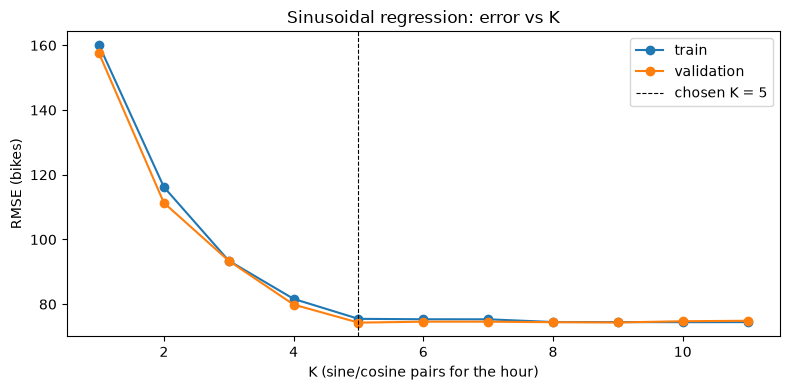

K,1,2,3,4,5,6,7,8,9,10,11
columns,15.0,19.0,23.0,27.0,31.0,35.0,39.0,43.0,47.0,51.0,55.0
train RMSE,160.0,116.2,93.4,81.6,75.5,75.3,75.3,74.5,74.5,74.4,74.5
validation RMSE,157.5,111.3,93.4,79.9,74.3,74.6,74.6,74.4,74.3,74.7,74.9


In [21]:
# improvement 2: feature engineering with sinusoidal features
# replace hr and mnth with sine/cosine waves so the model can learn a smooth daily cycle where 23:00 sits next to 00:00
def add_sinusoidal(X, K=4):
    out = X.drop(columns=['hr', 'mnth']).copy()
    for k in range(1, K + 1):
        sin_hr = np.sin(2 * np.pi * k * X['hr'] / 24)
        cos_hr = np.cos(2 * np.pi * k * X['hr'] / 24)
        out[f'hr_sin{k}'] = sin_hr
        out[f'hr_cos{k}'] = cos_hr
        # separate daily curve for working days (commute peaks)
        out[f'hr_sin{k}_work'] = sin_hr * X['workingday']
        out[f'hr_cos{k}_work'] = cos_hr * X['workingday']
    out['mnth_sin'] = np.sin(2 * np.pi * (X['mnth'] - 1) / 12)
    out['mnth_cos'] = np.cos(2 * np.pi * (X['mnth'] - 1) / 12)
    return out

# K (number of sine/cosine pairs) is a hyperparameter: choose it on the validation set
K_values = list(range(1, 12))
K_train_rmse, K_val_rmse = [], []
for K in K_values:
    X_K = add_sinusoidal(X, K=K)
    m = LinearRegression().fit(X_K.loc[X_tr.index], np.log1p(y_tr))
    K_train_rmse.append(mean_squared_error(y_tr, np.expm1(m.predict(X_K.loc[X_tr.index]))) ** 0.5)
    K_val_rmse.append(mean_squared_error(y_val, np.expm1(m.predict(X_K.loc[X_val.index]))) ** 0.5)

# smallest K within 1 bike of the best validation error (prefer the simpler model when the gain is negligible)
best_K = next(K for K, v in zip(K_values, K_val_rmse) if v <= min(K_val_rmse) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(K_values, K_train_rmse, marker='o', label='train')
ax.plot(K_values, K_val_rmse, marker='o', label='validation')
ax.axvline(best_K, color='k', linestyle='--', linewidth=0.8, label=f'chosen K = {best_K}')
ax.set(xlabel='K (sine/cosine pairs for the hour)', ylabel='RMSE (bikes)',
       title='Sinusoidal regression: error vs K')
ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({'K': K_values, 'columns': [add_sinusoidal(X, K=K).shape[1] for K in K_values],
              'train RMSE': K_train_rmse, 'validation RMSE': K_val_rmse}).round(1).set_index('K').T

**Choosing K:**

- **K = 1:** RMSE 160.0 (train) and 157.5 (validation). One wave per day can't represent two commute peaks, so the model underfits.
- **K = 5 (chosen):** validation RMSE 74.3. Beyond this, both errors level off at about 74-75, so more waves add columns without improving the fit.
- **No overfitting at any K.** The train and validation curves stay within 5 bikes of each other. Even at K = 11 (55 columns), 10,427 training rows are plenty to estimate the parameters.

In [22]:
# fit the sinusoidal model with the chosen K on the full training set
X_sin = add_sinusoidal(X, K=best_K)
print('columns after the sinusoidal transform:', X_sin.shape[1])

# initialize and fit, training on log(cnt + 1) so predictions can't go negative
sin_model = LinearRegression()
sin_model.fit(X_sin.loc[X_train.index], np.log1p(y_train))

# check predictions scores (convert back from log scale first)
sin_pred = np.expm1(sin_model.predict(X_sin.loc[X_test.index]))
sin_train_pred = np.expm1(sin_model.predict(X_sin.loc[X_train.index]))

print(f'MSE  {mean_squared_error(y_test, sin_pred):.1f}')
print(f'RMSE {mean_squared_error(y_test, sin_pred) ** 0.5:.1f}')
print(f'MAE  {mean_absolute_error(y_test, sin_pred):.1f}')
print(f'R2   {r2_score(y_test, sin_pred):.3f}')

# training scores, to compare with the test scores for signs of over- or underfitting
print(f'train RMSE {mean_squared_error(y_train, sin_train_pred) ** 0.5:.1f} | train R2 {r2_score(y_train, sin_train_pred):.3f}')

columns after the sinusoidal transform: 31
MSE  5647.4
RMSE 75.1
MAE  43.8
R2   0.822
train RMSE 74.6 | train R2 0.832


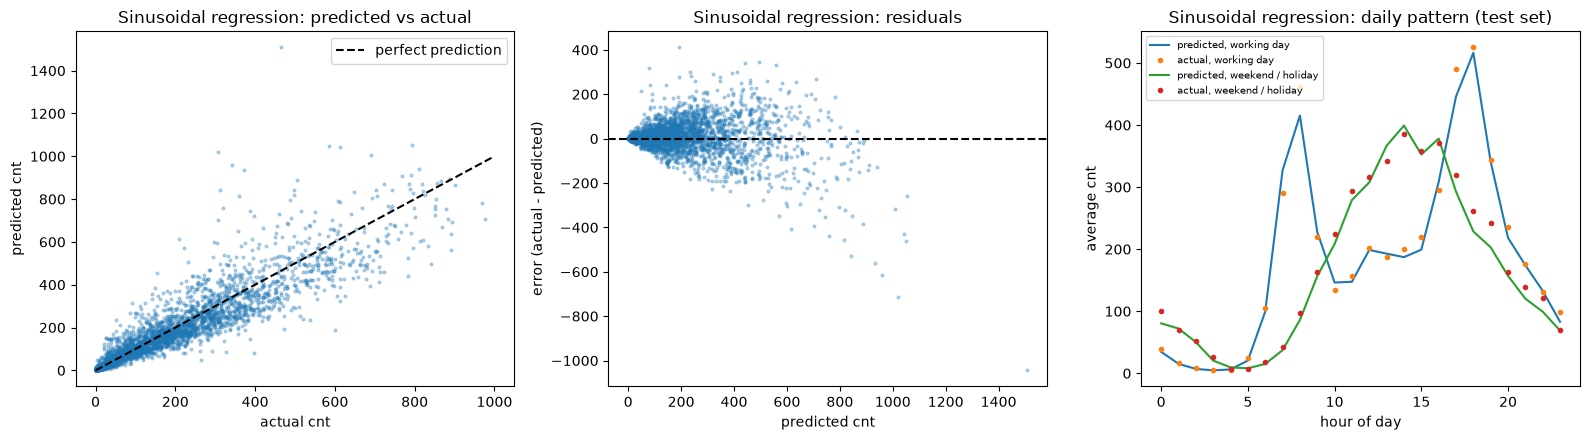

In [23]:
# plot scores
# predicted vs actual counts of bikes used
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(y_test, sin_pred, s=4, alpha=0.3)
axes[0].plot([0, 1000], [0, 1000], 'k--', label='perfect prediction')
axes[0].set(xlabel='actual cnt', ylabel='predicted cnt', title='Sinusoidal regression: predicted vs actual')
axes[0].legend()

# residuals (errors)
sin_residuals = y_test - sin_pred
axes[1].scatter(sin_pred, sin_residuals, s=4, alpha=0.3)
axes[1].axhline(0, color='k', linestyle='--')
axes[1].set(xlabel='predicted cnt', ylabel='error (actual - predicted)', title='Sinusoidal regression: residuals')

# the daily pattern: average prediction vs average actual count for each hour of the test set
test_profile = pd.DataFrame({'hr': X_test['hr'], 'workingday': X_test['workingday'],
                             'actual': y_test, 'predicted': sin_pred})
for workingday, label in [(1, 'working day'), (0, 'weekend / holiday')]:
    profile = test_profile[test_profile['workingday'] == workingday].groupby('hr')[['actual', 'predicted']].mean()
    axes[2].plot(profile.index, profile['predicted'], label=f'predicted, {label}')
    axes[2].plot(profile.index, profile['actual'], 'o', markersize=3, label=f'actual, {label}')
axes[2].set(xlabel='hour of day', ylabel='average cnt', title='Sinusoidal regression: daily pattern (test set)')
axes[2].legend(fontsize=7)

plt.tight_layout()
plt.show()

**Results (K = 5, 31 columns):**

| | RMSE | MAE | R² |
| --- | --- | --- | --- |
| Test | 75.1 | 43.8 | 0.822 |
| Train | 74.6 | | 0.832 |

- Compared with the baseline, test RMSE falls from 139.3 to 75.1 and R² rises from 0.387 to 0.822, with only 20 extra columns. It also beats the regularized degree-4 polynomial (102.2) with 1,333 fewer columns, which shows that the right features matter more than more features.
- **Train and test errors are almost identical,** so the model doesn't overfit; the remaining error is bias.
- **The daily pattern plot shows the model still smooths the commute peaks.** At 8:00 on working days it predicts 415 bikes on average, against 461 actual; at 17:00 it's 446 against 491. Weekend afternoons are close (399 against 385 at 14:00).
- **Residuals:** 83 test hours are off by more than 200 bikes, against 424 for the baseline. A few predictions overshoot badly, up to 1,508 bikes, above the dataset's maximum of 977: a modest error on the log scale becomes a large error once converted back with the exponential.

### 6.3 Gradient boosting with early stopping

**Boosting** builds trees one after another. Each new, small tree is fitted to the errors the current ensemble still makes (for squared error, the gradient of the loss is the residuals), and its contribution is scaled down by a learning rate. Random forests reduce variance by averaging independent trees; boosting instead reduces bias step by step. In effect it's gradient descent on the cost, one tree at a time.

`HistGradientBoostingRegressor` groups each feature's values into at most 255 bins (a histogram), which makes it fast. It's set up with up to 63 leaves per tree and up to 500 trees.

**Early stopping** acts as regularization (Lecture 8's "fewer epochs for training"). With more than 10,000 rows it's on by default: 10% of the training data is held out as a validation set, and training stops once the validation loss hasn't improved for 10 iterations.

In [24]:
# initialize and fit the histogram gradient boosting model
# trees are built one after another, each one correcting the errors of the trees before it
hgb = HistGradientBoostingRegressor(max_iter=500, max_leaf_nodes=63, random_state=42)
hgb.fit(X_train, y_train)   # unscaled is fine for tree models

# check predictions scores
hgb_pred = hgb.predict(X_test)
hgb_train_pred = hgb.predict(X_train)

print(f'MSE  {mean_squared_error(y_test, hgb_pred):.1f}')
print(f'RMSE {mean_squared_error(y_test, hgb_pred) ** 0.5:.1f}')
print(f'MAE  {mean_absolute_error(y_test, hgb_pred):.1f}')
print(f'R2   {r2_score(y_test, hgb_pred):.3f}')

# training scores, to compare with the test scores for signs of over- or underfitting
print(f'train RMSE {mean_squared_error(y_train, hgb_train_pred) ** 0.5:.1f} | train R2 {r2_score(y_train, hgb_train_pred):.3f}')
print('negative predictions:', (hgb_pred < 0).sum())

# early stopping is on by default for more than 10,000 rows: 10% of the training data is held out
# as a validation set, and training stops when the validation loss stops improving
print('early stopping used:', hgb.do_early_stopping_, '| iterations:', hgb.n_iter_, 'of', hgb.max_iter)

MSE  1481.1
RMSE 38.5
MAE  23.3
R2   0.953
train RMSE 27.4 | train R2 0.977
negative predictions: 50
early stopping used: True | iterations: 193 of 500


**Results:**

- **Test:** RMSE 38.5, MAE 23.3, R² 0.953. Better than the random forest (RMSE 42.0).
- **Train:** RMSE 27.4. The train-test gap is 11 bikes, against 26 for the random forest, so there's **less overfitting**.
- Training stopped at iteration 193 of 500.
- **Limitation:** 50 test hours get a negative prediction (as low as −31.7). The model doesn't know that counts can't be negative. Clipping predictions at 0, or using a log target, would fix this.

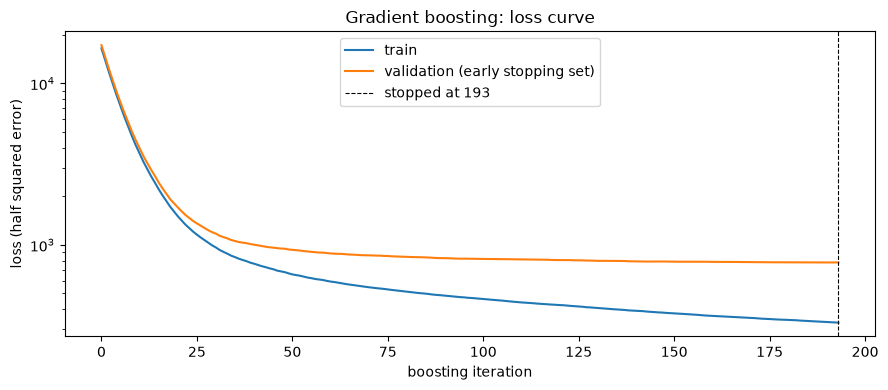

In [25]:
# loss curve: the loss after every boosting iteration, on the training data and the held-out validation set
# scikit-learn stores the negative loss, so flip the sign; the loss is half the squared error
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(-hgb.train_score_, label='train')
ax.plot(-hgb.validation_score_, label='validation (early stopping set)')
ax.axvline(hgb.n_iter_, color='k', linestyle='--', linewidth=0.8, label=f'stopped at {hgb.n_iter_}')
ax.set(xlabel='boosting iteration', ylabel='loss (half squared error)', yscale='log',
       title='Gradient boosting: loss curve')
ax.legend()
plt.tight_layout()
plt.show()

**Loss curve:**

- Both losses fall quickly over the first 25 or so iterations, while the model is still underfitting.
- After about 50 iterations, the validation loss levels off (932 at iteration 50, 778 at the end), while the training loss keeps falling (656 to 330). The widening gap shows the model starting to fit noise in the training data.
- Early stopping halted training at iteration 193, 10 iterations after the best validation loss (iteration 183). Without it, training would have continued to 500 iterations and only increased overfitting.

The loss is half the squared error, so doubling it gives the MSE. The final validation loss of 778 is an MSE of about 1,557, or an RMSE of about 39 bikes, which matches the test score.

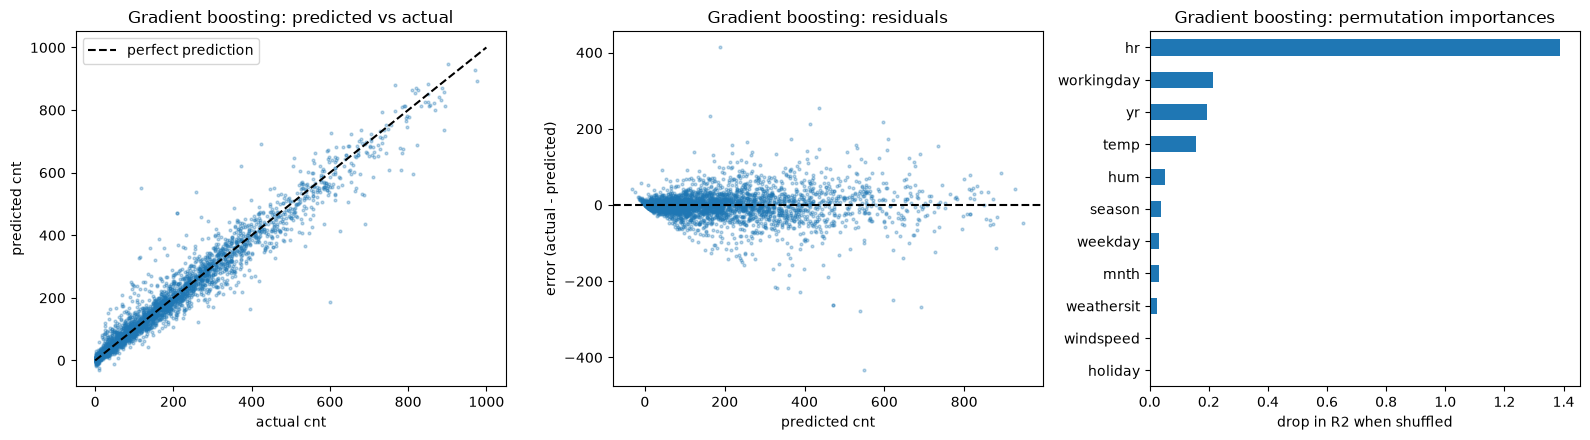

In [26]:
# plot scores
# predicted vs actual counts of bikes used
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(y_test, hgb_pred, s=4, alpha=0.3)
axes[0].plot([0, 1000], [0, 1000], 'k--', label='perfect prediction')
axes[0].set(xlabel='actual cnt', ylabel='predicted cnt', title='Gradient boosting: predicted vs actual')
axes[0].legend()

# residuals (errors)
hgb_residuals = y_test - hgb_pred
axes[1].scatter(hgb_pred, hgb_residuals, s=4, alpha=0.3)
axes[1].axhline(0, color='k', linestyle='--')
axes[1].set(xlabel='predicted cnt', ylabel='error (actual - predicted)', title='Gradient boosting: residuals')

# what the model learned: HistGradientBoosting has no feature_importances_, so shuffle
# each feature in the test set and measure how much R2 drops (bigger drop = more important)
perm = permutation_importance(hgb, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
hgb_importances = pd.Series(perm.importances_mean, index=X.columns).sort_values()
hgb_importances.plot.barh(ax=axes[2], title='Gradient boosting: permutation importances')
axes[2].set_xlabel('drop in R2 when shuffled')

plt.tight_layout()
plt.show()

**Plots:**

- As with the random forest, the predictions follow the diagonal closely. Only 15 test hours are off by more than 200 bikes.
- `HistGradientBoostingRegressor` has no built-in importances, so **permutation importance** is used instead: each feature in the test set is shuffled in turn, and the drop in R² is measured.
  - The biggest drops come from `hr` (1.39), `workingday` (0.21), `yr` (0.19) and `temp` (0.16).
  - `windspeed` and `holiday` are close to 0 (0.003).
  - `workingday` ranks second here, but only fourth in the random forest. This fits the hour × working-day interaction found in Part 2.
  - A drop larger than 1 is possible, because R² goes below 0 when the model is badly wrong.
  - The random forest's importances measure something different (how much each feature's splits reduce the error during training), so the two lists can only be compared roughly.

### 6.4 Hyperparameter tuning

The gradient boosting settings so far were chosen by hand. Lecture 9 describes two search strategies: **grid search** tries every combination and suits small search spaces, while **random search** samples combinations and is preferred when the space is large. Here there are 4 × 4 × 3 × 4 = 192 combinations, so random search tries 20 of them. Each is scored with **5-fold cross-validation** on the training set, so the test set plays no part in choosing the settings.

| Hyperparameter | Effect |
| --- | --- |
| `learning_rate` | How much each new tree contributes. Smaller values need more trees but learn more smoothly |
| `max_leaf_nodes` | How complex each tree can be |
| `min_samples_leaf` | Minimum number of rows in a leaf. Larger values give smoother predictions and less overfitting |
| `l2_regularization` | L2 penalty on large leaf values, the tree equivalent of Ridge's λ |

Candidate values move in rough orders of magnitude (0.03 to 0.2, 0 to 10), as Lecture 9 suggests. `early_stopping=True` is set explicitly, so every candidate, and every training size in the learning curves in Part 7, is regularized the same way. The default only switches it on above 10,000 rows.

In [27]:
# hyperparameter tuning: random search with 5-fold cross-validation on the training set only
# (the test set stays untouched until the final comparison)
param_space = {
    'learning_rate': [0.03, 0.05, 0.1, 0.2],
    'max_leaf_nodes': [15, 31, 63, 127],
    'min_samples_leaf': [10, 20, 50],
    'l2_regularization': [0.0, 0.1, 1.0, 10.0],
}
# early_stopping=True so every candidate (and every learning-curve size later) stops the same way;
# the default only switches it on above 10,000 rows
search = RandomizedSearchCV(
    HistGradientBoostingRegressor(max_iter=1000, early_stopping=True, random_state=42),
    param_space, n_iter=20, cv=5, scoring='neg_root_mean_squared_error', random_state=42, n_jobs=-1)
search.fit(X_train, y_train)

print('best settings:', search.best_params_)
print(f'best cross-validation RMSE: {-search.best_score_:.1f}')

hgb_tuned = search.best_estimator_
hgb_tuned_pred = hgb_tuned.predict(X_test)

print(f'MSE  {mean_squared_error(y_test, hgb_tuned_pred):.1f}')
print(f'RMSE {mean_squared_error(y_test, hgb_tuned_pred) ** 0.5:.1f}')
print(f'MAE  {mean_absolute_error(y_test, hgb_tuned_pred):.1f}')
print(f'R2   {r2_score(y_test, hgb_tuned_pred):.3f}')

# the 5 best settings tried, to see how sensitive the model is to them
tried = pd.DataFrame(search.cv_results_)
tried['CV RMSE'] = (-tried['mean_test_score']).round(1)
tried.sort_values('CV RMSE')[['param_learning_rate', 'param_max_leaf_nodes', 'param_min_samples_leaf',
                               'param_l2_regularization', 'CV RMSE']].head()

best settings: {'min_samples_leaf': 10, 'max_leaf_nodes': 127, 'learning_rate': 0.03, 'l2_regularization': 10.0}
best cross-validation RMSE: 39.7
MSE  1442.5
RMSE 38.0
MAE  22.5
R2   0.954


,param_learning_rate,param_max_leaf_nodes,param_min_samples_leaf,param_l2_regularization,CV RMSE
14,0.03,127,10,10.0,39.7
5,0.10,127,10,10.0,39.8
17,0.05,127,10,0.1,39.8
9,0.03,127,10,0.0,39.9
7,0.05,63,10,0.0,39.9


**Results:**

- **Best settings:** `learning_rate` 0.03, `max_leaf_nodes` 127, `min_samples_leaf` 10, `l2_regularization` 10, with a cross-validation RMSE of 39.7.
- **Test:** RMSE 38.0, MAE 22.5, R² 0.954, against 38.5, 23.3 and 0.953 before tuning. That's an improvement of about 1%.
- **The top five settings are all within 0.2 RMSE of each other** (39.7-39.9). The model isn't sensitive to these hyperparameters, so the original settings were already close to the best, and the remaining error isn't a tuning problem.
- The best settings all use small leaves (`min_samples_leaf` 10) and mostly large trees (127 leaves). Flexible trees work well here when they're controlled by early stopping and L2 regularization.

## Part 7: Experimental analysis

This part compares all the models: learning curves for the improved models, hour-by-hour predictions, a stricter test on an unseen future period, and a summary table and chart.

sinusoidal regression        train RMSE   74.6 | validation RMSE   74.8
random forest                train RMSE   16.5 | validation RMSE   44.3
gradient boosting (tuned)    train RMSE   25.5 | validation RMSE   39.9


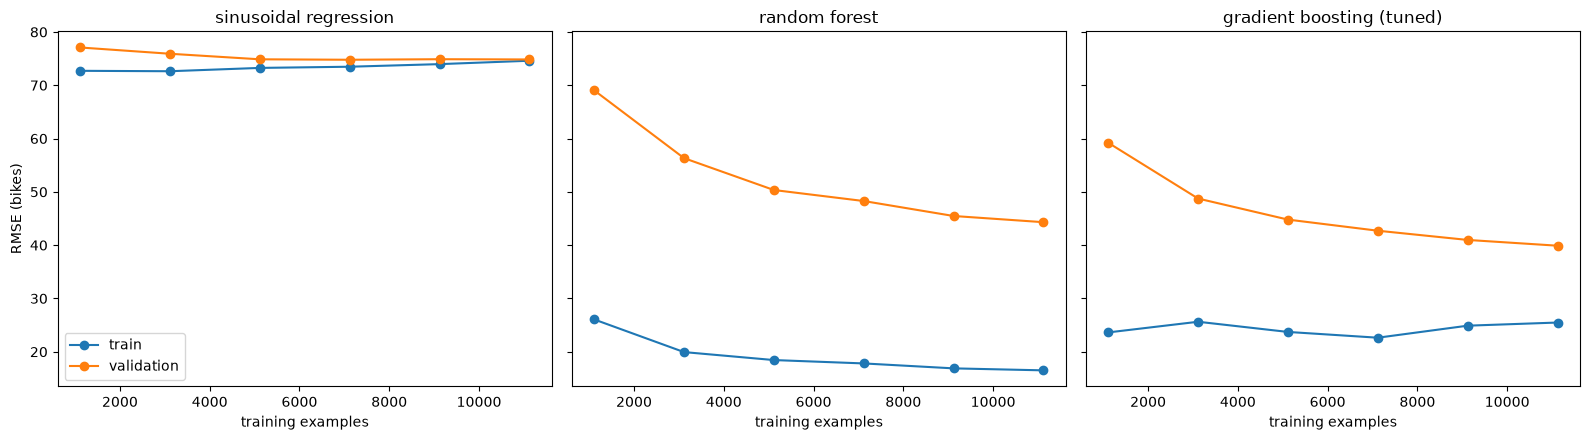

In [28]:
# learning curves for the improved models: error vs amount of training data (5-fold CV)
# TransformedTargetRegressor applies the same log(cnt + 1) target as the sinusoidal model inside each fold
models = {
    'sinusoidal regression': (TransformedTargetRegressor(LinearRegression(), func=np.log1p, inverse_func=np.expm1),
                              X_sin.loc[X_train.index]),
    'random forest': (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), X_train),
    'gradient boosting (tuned)': (clone(hgb_tuned), X_train),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (name, (model, X_lc)) in zip(axes, models.items()):
    sizes, lc_train, lc_val = learning_curve(
        model, X_lc, y_train, cv=5, train_sizes=np.linspace(0.1, 1.0, 6),
        scoring='neg_root_mean_squared_error', n_jobs=-1)
    ax.plot(sizes, -lc_train.mean(axis=1), marker='o', label='train')
    ax.plot(sizes, -lc_val.mean(axis=1), marker='o', label='validation')
    ax.set(xlabel='training examples', title=name)
    print(f'{name:28s} train RMSE {-lc_train.mean(axis=1)[-1]:6.1f} | validation RMSE {-lc_val.mean(axis=1)[-1]:6.1f}')
axes[0].set_ylabel('RMSE (bikes)')
axes[0].legend()
plt.tight_layout()
plt.show()

**Learning curves** (compare with the baseline's in Part 5, where both errors converged at about 142):

- **Sinusoidal regression:** the curves converge at about 75 (train 74.6, validation 74.8). It's still **high bias**, but at half the baseline's error: better features lowered the plateau, and more data still won't help.
- **Random forest:** there's a large gap (train 16.5, validation 44.3), but the validation error is still falling at the full training size. This is **high variance**, and more data would still help.
- **Gradient boosting (tuned):** it has the lowest validation error (39.9), still falling slowly, and its training error of about 25 means a smaller gap than the random forest's. Early stopping and L2 regularization keep its variance lower.

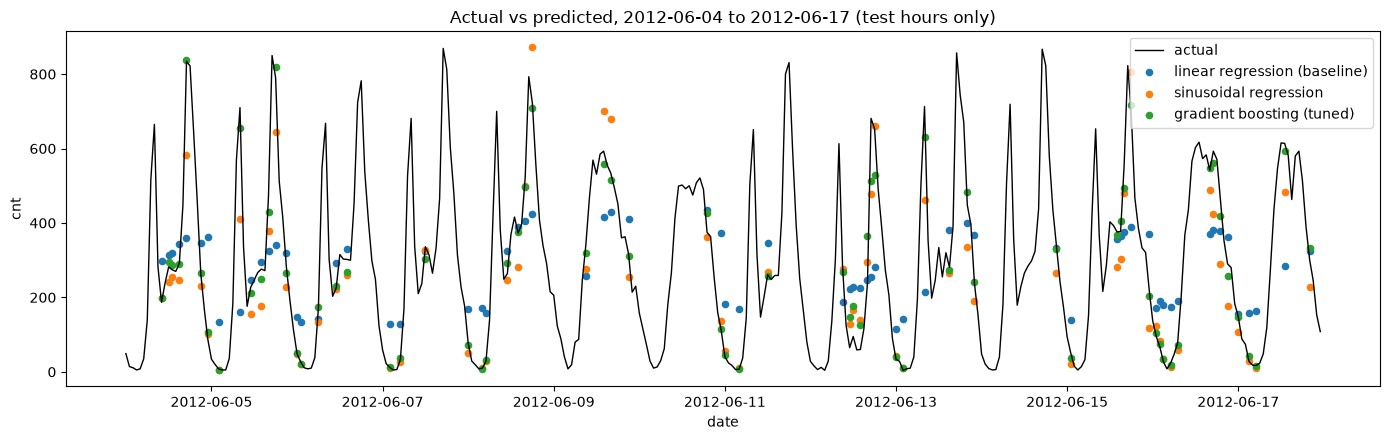

In [29]:
# actual vs predicted, hour by hour, for two weeks
# only test-set hours get a prediction, since the models already saw the training hours
start, end = '2012-06-04', '2012-06-17'
period = df[(df['dteday'] >= start) & (df['dteday'] <= end)]
timestamps = period['dteday'] + pd.to_timedelta(period['hr'], unit='h')

test_hours = period.index.intersection(X_test.index)
test_times = timestamps.loc[test_hours]

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(timestamps, period['cnt'], color='black', linewidth=1, label='actual')
ax.scatter(test_times, lin.predict(X.loc[test_hours]), s=20, label='linear regression (baseline)')
ax.scatter(test_times, np.expm1(sin_model.predict(X_sin.loc[test_hours])), s=20, label='sinusoidal regression')
ax.scatter(test_times, hgb_tuned.predict(X.loc[test_hours]), s=20, label='gradient boosting (tuned)')
ax.set(xlabel='date', ylabel='cnt', title=f'Actual vs predicted, {start} to {end} (test hours only)')
ax.legend()
plt.tight_layout()
plt.show()

**Two weeks of predictions:**

- The black line shows the real pattern: two sharp peaks on each working day, and a single rounded hump on the weekend of 9-10 June.
- The **linear baseline** stays in a narrow band and misses every peak and trough.
- **Sinusoidal regression** follows the daily shape but undershoots several peaks, matching the smoothed daily pattern in Part 6.
- **Gradient boosting** lands close to the line at the peaks and the troughs.

### Time-based split

The random split treats the hours as **i.i.d.** (independent and identically distributed). In reality neighbouring hours of the same day are very similar, so the test set isn't fully unseen. In practice, a model like this would be used to predict the future.

This test trains each model, with the same settings, on the first 80% of the hours (1 January 2011 to 7 August 2012) and tests it on the last 20% (7 August to 31 December 2012).

In [30]:
# time-based split: train on the first 80% of hours, test on the last 20% (Aug-Dec 2012)
# the random split assumes the hours are i.i.d., but neighbouring hours are not independent;
# this checks how well each model predicts a period it has never seen
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X, y, test_size=0.2, shuffle=False)
print('train:', df.loc[X_train_t.index, 'dteday'].min().date(), 'to', df.loc[X_train_t.index, 'dteday'].max().date())
print('test: ', df.loc[X_test_t.index, 'dteday'].min().date(), 'to', df.loc[X_test_t.index, 'dteday'].max().date())

# retrain each model with the same settings on the earlier data
lin_t = clone(lin).fit(X_train_t, y_train_t)
ridge_t = clone(ridge).fit(X_train_t, y_train_t)
sin_model_t = LinearRegression().fit(X_sin.loc[X_train_t.index], np.log1p(y_train_t))
rf_t = clone(rf).fit(X_train_t, y_train_t)
hgb_t = clone(hgb).fit(X_train_t, y_train_t)
hgb_tuned_t = clone(hgb_tuned).fit(X_train_t, y_train_t)

lin_pred_t = lin_t.predict(X_test_t)
ridge_pred_t = ridge_t.predict(X_test_t)
sin_pred_t = np.expm1(sin_model_t.predict(X_sin.loc[X_test_t.index]))
rf_pred_t = rf_t.predict(X_test_t)
hgb_pred_t = hgb_t.predict(X_test_t)
hgb_tuned_pred_t = hgb_tuned_t.predict(X_test_t)

train: 2011-01-01 to 2012-08-07
test:  2012-08-07 to 2012-12-31


In [31]:
# compare all models on the random split and the time-based split
predictions = {
    'linear regression (baseline)': (lin_pred, lin_pred_t),
    'polynomial degree 4 + Ridge': (ridge_pred, ridge_pred_t),
    'sinusoidal regression': (sin_pred, sin_pred_t),
    'random forest': (rf_pred, rf_pred_t),
    'gradient boosting': (hgb_pred, hgb_pred_t),
    'gradient boosting (tuned)': (hgb_tuned_pred, hgb_tuned_pred_t),
}
results = pd.DataFrame({
    name: {
        'MSE (random)': mean_squared_error(y_test, pred),
        'RMSE (random)': mean_squared_error(y_test, pred) ** 0.5,
        'MAE (random)': mean_absolute_error(y_test, pred),
        'R2 (random)': r2_score(y_test, pred),
        'MSE (time)': mean_squared_error(y_test_t, pred_t),
        'RMSE (time)': mean_squared_error(y_test_t, pred_t) ** 0.5,
        'MAE (time)': mean_absolute_error(y_test_t, pred_t),
        'R2 (time)': r2_score(y_test_t, pred_t),
    }
    for name, (pred, pred_t) in predictions.items()
}).T.round(3)
results

,MSE (random),RMSE (random),MAE (random),R2 (random),MSE (time),RMSE (time),MAE (time),R2 (time)
linear regression (baseline),19405.901,139.305,104.837,0.387,33668.722,183.490,138.640,0.307
polynomial degree 4 + Ridge,10452.394,102.237,71.902,0.670,81883.856,286.154,205.326,-0.684
sinusoidal regression,5647.358,75.149,43.804,0.822,6165.777,78.522,49.981,0.873
random forest,1763.126,41.990,24.637,0.944,4908.334,70.060,45.381,0.899
gradient boosting,1481.109,38.485,23.258,0.953,4193.695,64.759,42.411,0.914
gradient boosting (tuned),1442.542,37.981,22.536,0.954,4291.715,65.511,42.270,0.912


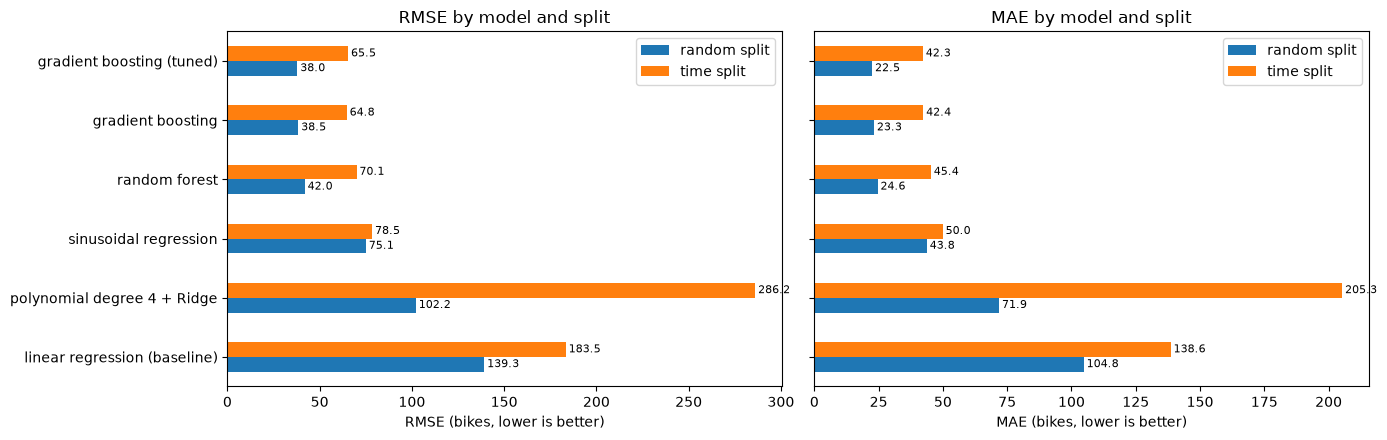

In [32]:
# compare the errors visually: RMSE and MAE for each model on both splits
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, metric in zip(axes, ['RMSE', 'MAE']):
    results[[f'{metric} (random)', f'{metric} (time)']].plot.barh(ax=ax)
    ax.set(xlabel=f'{metric} (bikes, lower is better)', title=f'{metric} by model and split')
    ax.legend(['random split', 'time split'])
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f', padding=2, fontsize=8)
plt.tight_layout()
plt.show()

### Discussion

| Model | RMSE (random) | R² (random) | RMSE (time) | R² (time) |
| --- | --- | --- | --- | --- |
| Linear regression (baseline) | 139.3 | 0.387 | 183.5 | 0.307 |
| Polynomial degree 4 + Ridge | 102.2 | 0.670 | 286.2 | −0.684 |
| Sinusoidal regression | 75.1 | 0.822 | 78.5 | 0.873 |
| Random forest | 42.0 | 0.944 | 70.1 | 0.899 |
| Gradient boosting | 38.5 | 0.953 | 64.8 | 0.914 |
| Gradient boosting (tuned) | 38.0 | 0.954 | 65.5 | 0.912 |

- **Every model beats the baseline on the random split,** and gradient boosting is the best model on both splits. The tuned and untuned versions are within one bike of each other, so the gain from tuning isn't reliable.
- **Every model does worse on the time split, but by very different amounts.** RMSE rises by 32% for the baseline, 67% for the random forest, 68% for gradient boosting, and only about 5% for the sinusoidal model. The random-split scores were optimistic, especially for the tree models, which benefit from having seen neighbouring hours of the same day.
- **The Ridge polynomial model fails on the time split** (R² −0.684, worse than predicting the mean). It's accurate for August to October, but for November it predicts 90 bikes per hour on average against 213 actual, and 702 of its predictions are negative. In the time split, the training data covers 2012 only up to August, so combinations such as "2012 and November" were never seen. The degree-4 terms (products like `yr` × `mnth`³) then **extrapolate** badly. Regularization reduces variance within the range of the training data, but it can't fix extrapolation outside it.
- **The sinusoidal model generalizes best relative to its random-split score.** Its few smooth, periodic features extrapolate safely: a sine wave repeats, while a polynomial shoots off.
- **Its R² rises (0.822 to 0.873) even though its errors grow (RMSE 75.1 to 78.5).** R² measures error relative to the variance of the test set, and the time-split test period varies much more (a standard deviation of 220.5 bikes, against 178.0 for the random test set). Comparing R² across different test sets is misleading, so RMSE and MAE are the fairer measures.
- **MAE is much lower than RMSE for every model.** A small number of large errors, mostly at peak hours, make up a big share of the squared error.

## Part 8: Conclusions

### Main findings

1. **The hour of day is the key feature, and its effect depends on the type of day:** commute peaks on working days, a midday hump on weekends. Every model that did well had to capture this non-linear pattern and interaction.
2. **The linear baseline underfits.** Multiple linear regression reached only R² 0.387 (RMSE 139.3). Training and test errors were equal and the learning curve was flat, so the problem was high bias, not lack of data. Gradient descent and the normal equation found the same solution, confirming the model itself, not the optimizer, is the limit.
3. **Adding complexity shows the bias-variance tradeoff directly.** Polynomial features reduced the error up to degree 3, but at degree 4 (1,364 columns) the model overfit: training RMSE 99.4, validation RMSE 425, and weights up to 3,207. The random forest showed the same tradeoff with tree depth, though averaging kept its test error stable.
4. **Regularization and feature engineering both improve the linear model.** Ridge with λ = 100 (chosen on the validation set) shrank the weights and brought the degree-4 model to RMSE 102.2. Five pairs of sine/cosine hour features with a working-day interaction did better still, RMSE 75.1 (R² 0.822) with only 31 columns.
5. **Gradient boosting with early stopping was the best model,** with RMSE 38.5 (R² 0.953) and a smaller train-test gap than the random forest. Random-search tuning gave only a small further gain (RMSE 38.0).
6. **The random split is optimistic for forecasting.** On a time-based split, the tree models' RMSE grew by about 67% and the Ridge polynomial model collapsed (R² −0.684), while the sinusoidal model barely changed. Gradient boosting remained the best (RMSE 64.8).

### What worked

- Starting from a simple baseline and diagnosing it with training vs validation error and learning curves, which pointed to the right fix each time: more flexibility for high bias, regularization for high variance.
- Using the exploration to design features: sine/cosine basis functions, the working-day interaction and the log target turned plain linear regression into a strong model.
- Regularization (Ridge's λ, gradient boosting's early stopping and L2 penalty) to control overfitting.
- Choosing every hyperparameter on a validation set or with cross-validation, never on the test set.
- Testing on a time-based split, which showed how optimistic the random split was and exposed the polynomial model's extrapolation problem.

### What didn't work

- Generic polynomial features: they need many columns, overfit quickly, predict negative counts, and extrapolate badly to unseen periods.
- Adding more sine/cosine terms beyond K = 5 gave no further improvement.
- Hyperparameter tuning improved the random split by only about 1%, and was slightly worse on the time split.
- The linear models can't fully reach the commute peaks, and converting back from the log scale produced a few very large overshoots (up to 1,508 bikes).
- Gradient boosting predicted negative counts for 50 test hours.

### What I learned

- **Diagnose before improving.** Comparing training and validation error showed whether a model suffered from bias or variance, and that decided the next step.
- **Better features can beat more features.** 31 well-designed columns outperformed 1,364 polynomial ones.
- **How a model is evaluated matters as much as which model is chosen.** The same models gave very different scores depending on whether the hours were treated as i.i.d.
- **R² can mislead** when it's compared across different test sets.

### Limitations and future work

- Adding the rentals from previous hours (lag features) would suit next-hour forecasting.
- Clipping negative predictions, or training gradient boosting on a log target.
- Using time-series cross-validation (`TimeSeriesSplit`) for tuning, so the tuning also respects time order.
- Trying L1 (Lasso) or Elastic Net regularization to see which polynomial terms matter.
- In the linear models, categorical codes such as `weekday` are still treated as numbers.